In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244081123

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] exp01
[学号]       20244081123
[机器指纹] b47d9754c73871cb
[RUN_ID]   20244081123-b47d9754c73871cb


## 一、围绕半圆定律

对 $n\times n$ 的 Wigner 矩阵，当 $n\to\infty$ 时特征值的经验分布收敛到半圆密度

$$f(x)=\begin{cases}\dfrac{1}{2\pi}\sqrt{4-x^2}, & |x|\le 2,\\[4pt] 0, & |x|>2.\end{cases}$$

构造方法：对 $1\le i\le j\le n$ 独立地从 $N(0,\,1/n)$ 抽取 $Z_{ij}$，再令 $Z_{ji}=Z_{ij}$，得到对称随机矩阵 $Z$。

In [2]:
import numpy as np
import matplotlib.pyplot as plt


def wigner_density(x):
    """返回半圆密度在 x 处的值；对标量输入返回 float，对数组输入返回 ndarray。"""
    x = np.asarray(x, dtype=float)
    density = np.where(
        np.abs(x) <= 2,
        np.sqrt(np.maximum(4.0 - x ** 2, 0.0)) / (2.0 * np.pi),
        0.0,
    )
    return float(density) if density.ndim == 0 else density


# 同时验证 Python 与 NumPy 的整数、浮点数输入
print(wigner_density(0), wigner_density(1), wigner_density(3))
print(wigner_density(-2.0), wigner_density(np.int64(1)), wigner_density(np.float64(1.5)))
print(wigner_density(np.array([-2.0, -1.0, 0.0, 1.0, 2.0])))

0.3183098861837907 0.27566444771089604 0.0
0.0 0.27566444771089604 0.2105421996738962
[0.         0.27566445 0.31830989 0.27566445 0.        ]


In [3]:
def generate_wigner(n):
    """生成 n x n 的 Wigner 矩阵：上三角（含对角）元素 ~ N(0, 1/n)，对称填充。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    rows, cols = np.triu_indices(n)
    values = np.random.normal(0.0, np.sqrt(1.0 / n), size=len(rows))
    z = np.zeros((n, n), dtype=float)
    z[rows, cols] = values
    z[cols, rows] = values          # 对称填充（对角线自赋值，不影响结果）
    return z


np.random.seed(2024)
z = generate_wigner(4)
print("是否对称:", np.allclose(z, z.T))
print(z)

for bad in (0, -3, 2.5, "5"):
    try:
        generate_wigner(bad)
    except Exception as exc:
        print(f"输入 {bad!r} -> {type(exc).__name__}: {exc}")

是否对称: True
[[ 0.83402366  0.36867386 -0.10076888 -0.07545597]
 [ 0.36867386  0.4580259   0.58016482 -1.309981  ]
 [-0.10076888  0.58016482 -0.66264729  0.22999431]
 [-0.07545597 -1.309981    0.22999431  0.05102582]]
输入 0 -> ValueError: n 必须是正整数
输入 -3 -> ValueError: n 必须是正整数
输入 2.5 -> TypeError: n 必须是整数
输入 '5' -> TypeError: n 必须是整数


In [4]:
def get_spectrum(matrix):
    """返回 matrix 的全部特征值（实对称矩阵），按非递减顺序排列。"""
    return np.sort(np.linalg.eigvalsh(np.asarray(matrix)))


spec = get_spectrum(generate_wigner(5))
print(spec)
print("是否非递减:", np.all(np.diff(spec) >= 0))

[-1.33477474 -0.68978879 -0.19035571  0.81471409  1.69125165]
是否非递减: True


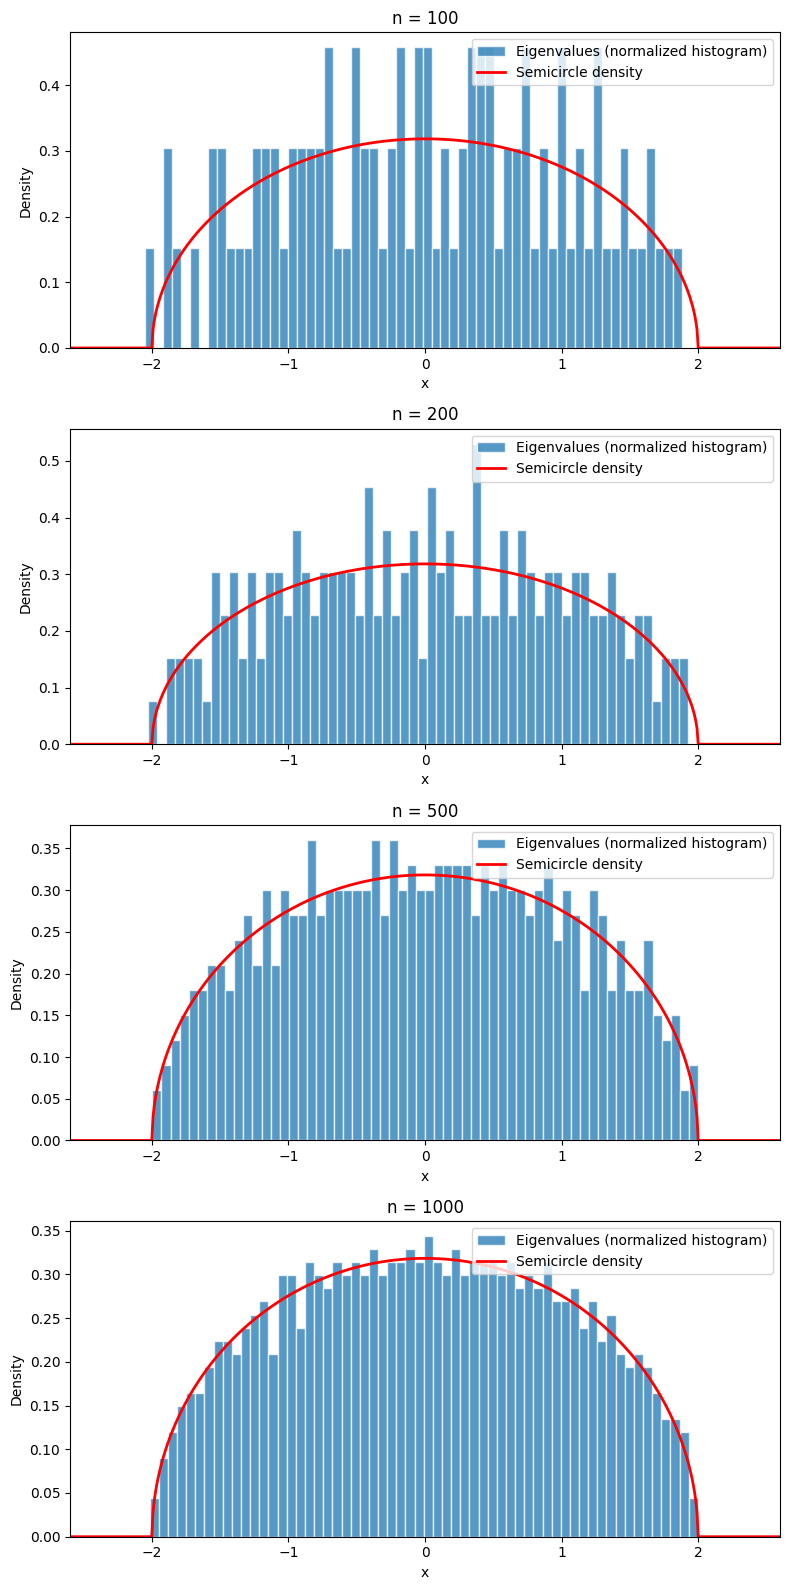

In [5]:
%matplotlib inline
np.random.seed(1)
sizes = [100, 200, 500, 1000]
x = np.linspace(-2.6, 2.6, 600)

fig, axes = plt.subplots(4, 1, figsize=(8, 16))
for ax, n in zip(axes, sizes):
    spectrum = get_spectrum(generate_wigner(n))
    ax.hist(spectrum, bins=60, density=True, color="tab:blue",
            alpha=0.75, edgecolor="white", label="Eigenvalues (normalized histogram)")
    ax.plot(x, wigner_density(x), color="red", linewidth=2, label="Semicircle density")
    ax.set_xlim(-2.6, 2.6)
    ax.set_title(f"n = {n}")
    ax.set_xlabel("x")
    ax.set_ylabel("Density")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

**图形说明：** $n=100$ 时直方图与红色半圆曲线仍有可见偏差（顶部不够圆滑、边缘抖动较明显）；$n=200$ 明显改善；$n=500$ 时曲线与直方图已基本重合；$n=1000$ 时拟合非常好，边缘在 $[-2,2]$ 之外几乎为零。因此 $n$ 大约达到 **500** 时，半圆密度就能较好地拟合特征值分布。

In [6]:
from scipy import stats


def semicircle_cdf(x):
    """半圆密度的累积分布函数。"""
    x = np.asarray(x, dtype=float)
    xc = np.clip(x, -2.0, 2.0)
    middle = 0.5 + xc * np.sqrt(4.0 - xc ** 2) / (4.0 * np.pi) + np.arcsin(xc / 2.0) / np.pi
    return np.where(x <= -2, 0.0, np.where(x >= 2, 1.0, middle))


# 可选任务：Kolmogorov–Smirnov 检验（分布参数已知，无需估计）
for n in sizes:
    spectrum = get_spectrum(generate_wigner(n))
    d, p = stats.kstest(spectrum, semicircle_cdf)
    print(f"n={n:4d}  KS 统计量 D={d:.4f}  p 值={p:.4f}")

n= 100  KS 统计量 D=0.0238  p 值=1.0000
n= 200  KS 统计量 D=0.0155  p 值=1.0000
n= 500  KS 统计量 D=0.0063  p 值=1.0000
n=1000  KS 统计量 D=0.0038  p 值=1.0000


KS 统计量 $D$ 随 $n$ 增大而单调减小（$n=100$ 时约 $0.024$，$n=200$ 时约 $0.016$，$n=500$ 时约 $0.006$，$n=1000$ 时约 $0.004$），与图形结论一致：矩阵阶数越大，特征值分布越接近半圆定律。

## 二、Conway 的生命游戏

棋盘用 $m\times n$ 的 NumPy 二维数组表示（1 为活细胞，0 为死细胞），边界环绕。每一步按规则同步更新所有细胞。

In [7]:
def is_valid_board(board):
    """若 board 是仅含 0/1 的二维 ndarray，则返回 True，否则返回 False。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2 or board.size == 0:
        return False
    return bool(np.isin(board, [0, 1]).all())


print(is_valid_board(np.array([[0, 1], [1, 0]])))          # True
print(is_valid_board(np.zeros((3, 3), dtype=int)))         # True
print(is_valid_board([[0, 1], [1, 0]]))                    # False：不是 ndarray
print(is_valid_board(np.array([0, 1, 0])))                 # False：不是二维
print(is_valid_board(np.array([[0, 2], [1, 0]])))          # False：含非 0/1 元素

True
True
False
False
False


In [8]:
def gol_step(board):
    """返回生命游戏棋盘的下一步状态；输入无效时抛出 ValueError。"""
    if not is_valid_board(board):
        raise ValueError("无效棋盘：必须是仅含 0/1 的二维 NumPy 数组")

    neighbors = sum(
        np.roll(np.roll(board, di, axis=0), dj, axis=1)
        for di in (-1, 0, 1)
        for dj in (-1, 0, 1)
        if (di, dj) != (0, 0)
    )
    alive = board == 1
    return np.where(alive & ((neighbors == 2) | (neighbors == 3)) | (~alive) & (neighbors == 3),
                    1, 0).astype(int)


# 测试：周期为 2 的“闪烁器”
blinker = np.zeros((5, 5), dtype=int)
blinker[2, 1:4] = 1
print("初始：\n", blinker)
print("下一步：\n", gol_step(blinker))
print("再下一步：\n", gol_step(gol_step(blinker)))

try:
    gol_step(np.array([[0, 2], [1, 0]]))
except ValueError as exc:
    print("异常:", exc)

初始：
 [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
下一步：
 [[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]
再下一步：
 [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
异常: 无效棋盘：必须是仅含 0/1 的二维 NumPy 数组


初始状态


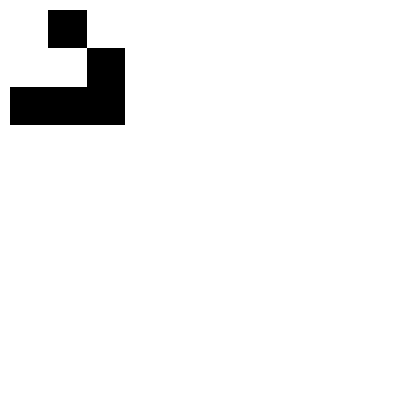

经过 4 步后（整体向右下平移一格）


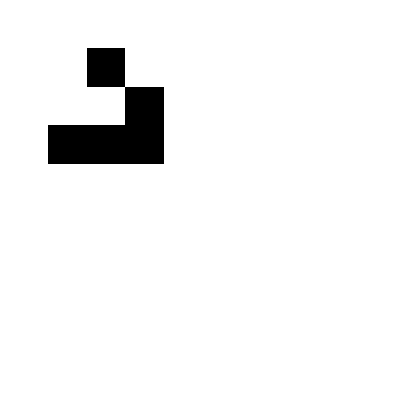

In [9]:
%matplotlib inline
def draw_gol_board(board):
    """把棋盘画成 m x n 个方格：活细胞黑色，死细胞白色，不显示网格与坐标轴。"""
    plt.figure(figsize=(5, 5))
    plt.imshow(board, cmap="gray_r", interpolation="nearest", vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()


# 滑翔机（glider）演示：每 4 步整体平移一格
glider = np.zeros((10, 10), dtype=int)
for r, c in [(0, 1), (1, 2), (2, 0), (2, 1), (2, 2)]:
    glider[r, c] = 1

print("初始状态")
draw_gol_board(glider)

for _ in range(4):
    glider = gol_step(glider)

print("经过 4 步后（整体向右下平移一格）")
draw_gol_board(glider)

## 三、使用 pandas DataFrame

iris 数据集包含 150 个样本，每行是萼片长度、萼片宽度、花瓣长度、花瓣宽度（单位 cm）与花卉种类。

In [10]:
import pandas as pd

df = pd.read_csv("iris.csv")
print("数据点个数:", len(df))
print("\n各列数据类型:")
print(df.dtypes)
print("\n列名:", df.columns.tolist())
print("\n花卉种类及数量:")
print(df["species"].value_counts())
df.head()

数据点个数: 150

各列数据类型:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

列名: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

花卉种类及数量:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**回答：** 数据集共有 **150** 个数据点；前四列均为 `float64`，`species` 为字符串（`object`/`str`）；列名为 `sepal_length, sepal_width, petal_length, petal_width, species`；共有 **3** 种花卉（setosa、versicolor、virginica），每类 50 个样本。

In [11]:
# 第 35、38 个数据行（从 0 开始的索引为 34、37）有误，进行更正
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]

df.loc[[34, 37]]

,sepal_length,sepal_width,petal_length,petal_width,species
34,4.9,3.1,1.5,0.2,setosa
37,4.9,3.6,1.4,0.1,setosa


In [12]:
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

df[["petal_length", "petal_width", "Petal.Ratio",
    "sepal_length", "sepal_width", "Sepal.Ratio"]].head()

,petal_length,petal_width,Petal.Ratio,sepal_length,sepal_width,Sepal.Ratio
0,1.4,0.2,7.0,5.1,3.5,1.457143
1,1.4,0.2,7.0,4.9,3.0,1.633333
2,1.3,0.2,6.5,4.7,3.2,1.468750
3,1.5,0.2,7.5,4.6,3.1,1.483871
4,1.4,0.2,7.0,5.0,3.6,1.388889


In [13]:
df.to_csv("iris_corrected.csv", index=False)

check = pd.read_csv("iris_corrected.csv")
print("已保存 iris_corrected.csv，形状:", check.shape)
check.loc[[34, 37]]

已保存 iris_corrected.csv，形状: (150, 7)


,sepal_length,sepal_width,petal_length,petal_width,species,Petal.Ratio,Sepal.Ratio
34,4.9,3.1,1.5,0.2,setosa,7.5,1.580645
37,4.9,3.6,1.4,0.1,setosa,14.0,1.361111


In [14]:
summary = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
summary

Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
species                                             
setosa      1.463063  1.268293  1.956522  0.118750  
versicolor  2.161290  1.764706  2.818182  0.228658  
virginica   2.169540  1.823529  2.961538  0.246992

**分组结果解读：** setosa 的 `Petal.Ratio` 均值最大且波动较大，因为它花瓣短而窄；versicolor 与 virginica 的花瓣比例相对更接近。`Sepal.Ratio` 在三类之间差异较小。所有统计量（均值、中位数、最小值、最大值、标准差）通过一次 `groupby(...).agg([...])` 得到。